Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


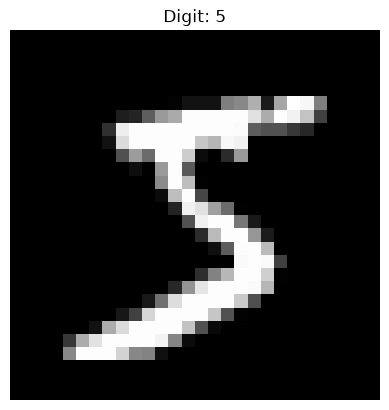

In [1]:

import struct
import numpy as np
import matplotlib.pyplot as plt


def load_mnist_images(path):
    with open(path, "rb") as f:
        # IDX3 header: magic number, image count, rows, columns
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))

        if magic != 2051:
            raise ValueError(f"Invalid image file: {path}")

        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(count, rows, cols)

    return images


def load_mnist_labels(path):
    with open(path, "rb") as f:
        # IDX1 header: magic number, label count
        magic, count = struct.unpack(">II", f.read(8))

        if magic != 2049:
            raise ValueError(f"Invalid label file: {path}")

        labels = np.frombuffer(f.read(), dtype=np.uint8)

    if len(labels) != count:
        raise ValueError("Label count does not match the header")

    return labels


# Load the four files
x_train = load_mnist_images("train-images.idx3-ubyte")
y_train = load_mnist_labels("train-labels.idx1-ubyte")

x_test = load_mnist_images("t10k-images.idx3-ubyte")
y_test = load_mnist_labels("t10k-labels.idx1-ubyte")

# Normalize pixels from [0, 255] to [0, 1]
x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

# Display a sample
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Digit: {y_train[0]}")
plt.axis("off")
plt.show()


In [2]:
from GDL_code_master.models.AE import Autoencoder

I0000 00:00:1792581945.002857   11114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792581945.062038   11114 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792581946.293283   11114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
class autoencoder_model(tf.keras.Model):
    def __init__(self, n_conv_layer):
        self.n_conv_layer = n_conv_layer
        self.model = self.build_model(n_conv_layer)





    def build_model(self, n_conv_layer):
        #encoder 
  
        inputs = Input(shape=(28, 28, 1) , name='encoder_input' )
        x = inputs
        for i in range(n_conv_layer ):
            x =keras.layers.Conv2D(filters = 32,
                                    kernel_size=(3,3), 
                                    activation='relu', 
                                    padding='same',
                                    name = f'conv2d_{i}')(x)
        shape_before_flatten = keras.backend.int_shape(x)[1:]
        print(shape_before_flatten)

        x = keras.layers.Flatten()(x)
        
        
        z = keras.layers.Dense(2, name='latent_vector')(x)


        ## decoder 

        decoder_input = z
        x = keras.layers.Dense(int(np.prod(shape_before_flatten)))(decoder_input)
        x = keras.layers.Reshape(shape_before_flatten)(x)
        for i in range(n_conv_layer):
            x = keras.layers.Conv2DTranspose(filters = 32,
                                            kernel_size=(3,3), 
                                            activation='relu', 
                                            padding='same',
                                            name = f'deconv2d_{i}')(x)
        outputs = keras.layers.Conv2DTranspose(filters = 1,
                                            kernel_size=(3,3),
                                            activation='sigmoid',
                                            padding='same',
                                            name='decoder_output')(x)
        return Model(inputs=inputs, outputs=outputs, name='autoencoder')


In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input, Model
import tensorflow.keras as keras 
from tensorflow.keras import backend , layers 
import pandas as pd 

I0000 00:00:1792686608.844886   43049 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792686609.005636   43049 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792686611.125431   43049 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [5]:

def autoencoder_model(n_conv_layer):
    inputs = Input(shape=(28, 28, 1), name="encoder_input")
    x = inputs

    for i in range(n_conv_layer):
        x = keras.layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same",
            name=f"conv2d_{i}"
        )(x)

    shape_before_flatten = keras.backend.int_shape(x)[1:]

    x = keras.layers.Flatten()(x)
    z = keras.layers.Dense(2, name="latent_vector")(x)

    # Decoder starts directly from z
    x = keras.layers.Dense(
        int(np.prod(shape_before_flatten))
    )(z)

    x = keras.layers.Reshape(shape_before_flatten)(x)

    for i in range(n_conv_layer):
        x = keras.layers.Conv2DTranspose(
            filters=32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same",
            name=f"deconv2d_{i}"
        )(x)

    outputs = keras.layers.Conv2DTranspose(
        filters=1,
        kernel_size=(3, 3),
        activation="sigmoid",
        padding="same",
        name="decoder_output"
    )(x)

    return Model(inputs=inputs, outputs=outputs, name="autoencoder")


model = autoencoder_model(3)

model.compile(
    optimizer=keras.optimizers.Adam(),
    loss=rms_pixel_error
)

model.summary()



Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_0 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 2)              │        50,178 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25088)          │        75,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deconv2d_0 (Conv2DTranspose)    │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deconv2d_1 (Conv2DTranspose)    │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deconv2d_2 (Conv2DTranspose)    │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output                  │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,291 (673.01 KB)

 Trainable params: 172,291 (673.01 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
def rms_pixel_error(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_true - y_pred)))
model = autoencoder_model(3)
model.compile(optimizer='adam', loss=rms_pixel_error, metrics=['accuracy'])


In [6]:
history = model.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20


I0000 00:00:1792686674.164184   43362 service.cc:153] XLA service 0x755ac4039fe0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792686674.164243   43362 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.22.0)
I0000 00:00:1792686674.227213   43362 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792686674.806517   43362 cuda_dnn.cc:461] Loaded cuDNN version 92200
I0000 00:00:1792686674.827283   43362 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3542__.11


  3/422 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - loss: 0.4798   

I0000 00:00:1792686682.446715   43362 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


419/422 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.2735

I0000 00:00:1792686691.117103   43362 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3542__.11
I0000 00:00:1792686693.074857   43879 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 8 bytes spill stores, 8 bytes spill loads



422/422 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - loss: 0.2443 - val_loss: 0.2206
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2176 - val_loss: 0.2111
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2118 - val_loss: 0.2087
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2088 - val_loss: 0.2050
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2068 - val_loss: 0.2042
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2054 - val_loss: 0.2023
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.2045 - val_loss: 0.2013
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.2033 - val_loss: 0.2007
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.2027 - val_loss: 0.2005
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2020 - val_loss: 0.1998
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2014 - val_loss: 0.1997
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/st

In [79]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=rms_pixel_error
)

In [80]:
print(x_train.shape)
print(x_train.dtype)
print(x_train.min(), x_train.max())

(60000, 28, 28)
float32
0.0 1.0


In [81]:
x_train = x_train[..., None]
x_test = x_test[..., None]

print(x_train.shape)
# (60000, 28, 28, 1)

(60000, 28, 28, 1)


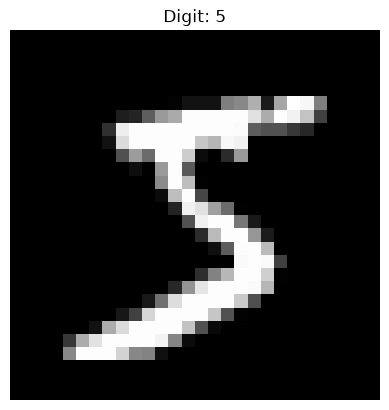

In [7]:
# Display a sample
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Digit: {y_train[0]}")
plt.axis("off")
plt.show()


In [8]:
y_pred = model.predict(x_test[0:1])# BATCH DIMANSSION SHOULD NOT BE REMOVED, OTHERWISE IT WILL THROW ERROR

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


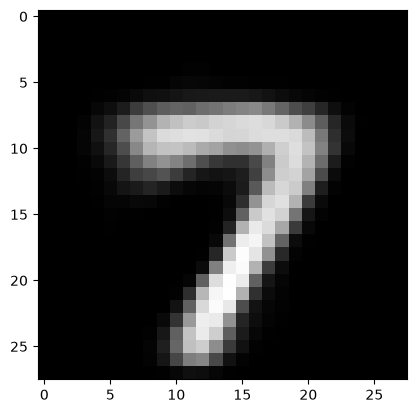

In [10]:
plt.imshow(y_pred[0], cmap="gray")

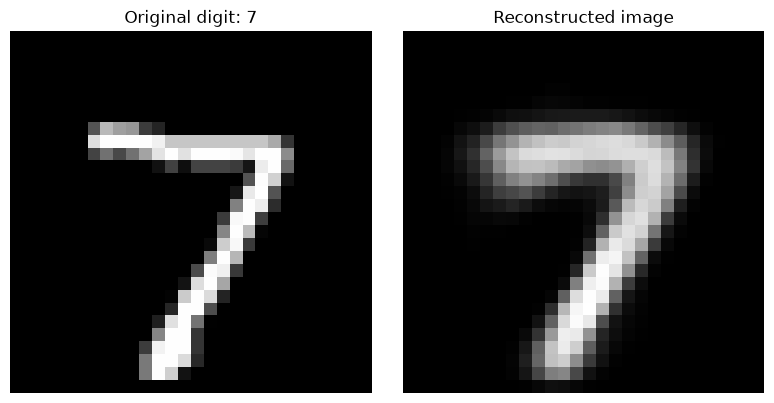

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample[0, :, :, 0], cmap="gray")
plt.title(f"Original digit: {y_test[0]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(prediction[0, :, :, 0], cmap="gray")
plt.title("Reconstructed image")
plt.axis("off")

plt.tight_layout()
plt.show()